# WEEK 8: Introduction to Machine Learning

MONDAY - Introduction to ML Concepts


In [1]:
# Cell 1: Understanding ML Concepts
# Supervised Learning: Has labeled data (features + target)
# Unsupervised Learning: No labels, find patterns

print("Machine Learning Types:")
print("1. Supervised: Classification, Regression")
print("2. Unsupervised: Clustering, Dimensionality Reduction")

# Features (X) and Target (y) example
import pandas as pd
import io

csv_data = """Age,Salary,City,Purchased
25,50000,Lagos,0
30,60000,Abuja,1
28,55000,Ibadan,1
22,45000,Lagos,0
35,70000,Lagos,1"""
df = pd.read_csv(io.StringIO(csv_data))
print("\nDataset:")
print(df)

# Features (X) and Target (y)
X = df[['Age', 'Salary']]
y = df['Purchased']
print(f"\nFeatures (X):\n{X}")
print(f"\nTarget (y):\n{y}")

Machine Learning Types:
1. Supervised: Classification, Regression
2. Unsupervised: Clustering, Dimensionality Reduction

Dataset:
   Age  Salary    City  Purchased
0   25   50000   Lagos          0
1   30   60000   Abuja          1
2   28   55000  Ibadan          1
3   22   45000   Lagos          0
4   35   70000   Lagos          1

Features (X):
   Age  Salary
0   25   50000
1   30   60000
2   28   55000
3   22   45000
4   35   70000

Target (y):
0    0
1    1
2    1
3    0
4    1
Name: Purchased, dtype: int64


In [2]:
# Cell 2: Classification vs Regression
import pandas as pd

# Classification: Predict categories
print("CLASSIFICATION EXAMPLE:")
print("Target: Purchased (0 or 1)")
print("Goal: Predict if customer will buy")

# Regression: Predict continuous values
print("\nREGRESSION EXAMPLE:")
print("Target: House Price ($250,000)")
print("Goal: Predict exact price")

# Key difference
print("\nDifference:")
print("Classification = Discrete categories")
print("Regression = Continuous numbers")

CLASSIFICATION EXAMPLE:
Target: Purchased (0 or 1)
Goal: Predict if customer will buy

REGRESSION EXAMPLE:
Target: House Price ($250,000)
Goal: Predict exact price

Difference:
Classification = Discrete categories
Regression = Continuous numbers


In [3]:
# Cell 3: Loading a Dataset for ML
import pandas as pd
import seaborn as sns

# Load Iris dataset
iris = sns.load_dataset("iris")
print("Iris Dataset:")
print(iris.head())
print(f"\nShape: {iris.shape}")
print(f"\nTarget classes: {iris['species'].unique()}")

# Features and target
X = iris.drop('species', axis=1)
y = iris['species']
print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")

Iris Dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Shape: (150, 5)

Target classes: ['setosa' 'versicolor' 'virginica']

Features shape: (150, 4)
Target shape: (150,)


TUESDAY - Train-Test Split


In [4]:
# Cell 1: Basic Train-Test Split
from sklearn.model_selection import train_test_split
import seaborn as sns
import pandas as pd

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Total samples: {len(X)}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Total samples: 150
Training samples: 120
Testing samples: 30


In [5]:
# Cell 2: Understanding random_state
from sklearn.model_selection import train_test_split
import seaborn as sns

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

# Without random_state (different results each run)
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, test_size=0.2)
print("Without random_state:")
print(f"First test index: {X_test1.index[0]}")

# With random_state (reproducible)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nWith random_state=42:")
print(f"First test index: {X_test2.index[0]}")

# Running again with same random_state gives same result
X_train3, X_test3, y_train3, y_test3 = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Same result: {X_test2.index[0] == X_test3.index[0]}")

Without random_state:
First test index: 97

With random_state=42:
First test index: 73
Same result: True


In [6]:
# Cell 3: Different Split Ratios
from sklearn.model_selection import train_test_split
import seaborn as sns

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

# 70-30 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("70-30 Split:")
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

# 90-10 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
print("\n90-10 Split:")
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

# 60-40 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
print("\n60-40 Split:")
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

70-30 Split:
Train: 105, Test: 45

90-10 Split:
Train: 135, Test: 15

60-40 Split:
Train: 90, Test: 60


WEDNESDAY - Feature Engineering & One-Hot Encoding

In [7]:
# Cell 1: Creating New Features
import pandas as pd
import io

csv_data = """Name,Age,Salary,JoinYear
Alice,25,50000,2020
Bob,30,60000,2019
Carol,28,55000,2021
David,22,45000,2022"""
df = pd.read_csv(io.StringIO(csv_data))
print("Original:")
print(df)

# Create new feature: Years of Experience
df['Experience'] = 2026 - df['JoinYear']
print("\nWith Experience feature:")
print(df)

# Create Salary per Age
df['Salary_per_Age'] = df['Salary'] / df['Age']
print("\nWith Salary per Age:")
print(df)

Original:
    Name  Age  Salary  JoinYear
0  Alice   25   50000      2020
1    Bob   30   60000      2019
2  Carol   28   55000      2021
3  David   22   45000      2022

With Experience feature:
    Name  Age  Salary  JoinYear  Experience
0  Alice   25   50000      2020           6
1    Bob   30   60000      2019           7
2  Carol   28   55000      2021           5
3  David   22   45000      2022           4

With Salary per Age:
    Name  Age  Salary  JoinYear  Experience  Salary_per_Age
0  Alice   25   50000      2020           6     2000.000000
1    Bob   30   60000      2019           7     2000.000000
2  Carol   28   55000      2021           5     1964.285714
3  David   22   45000      2022           4     2045.454545


In [8]:
# Cell 2: One-Hot Encoding with get_dummies()
import pandas as pd
import io

csv_data = """Name,City,Department,Salary
Alice,Lagos,IT,50000
Bob,Abuja,HR,60000
Carol,Ibadan,IT,55000
David,Lagos,Finance,45000"""
df = pd.read_csv(io.StringIO(csv_data))
print("Original:")
print(df)

# One-hot encode City
city_encoded = pd.get_dummies(df['City'], prefix='City')
print("\nCity One-Hot Encoded:")
print(city_encoded)

# Combine with original
df_encoded = pd.concat([df, city_encoded], axis=1)
print("\nCombined:")
print(df_encoded)

Original:
    Name    City Department  Salary
0  Alice   Lagos         IT   50000
1    Bob   Abuja         HR   60000
2  Carol  Ibadan         IT   55000
3  David   Lagos    Finance   45000

City One-Hot Encoded:
   City_Abuja  City_Ibadan  City_Lagos
0       False        False        True
1        True        False       False
2       False         True       False
3       False        False        True

Combined:
    Name    City Department  Salary  City_Abuja  City_Ibadan  City_Lagos
0  Alice   Lagos         IT   50000       False        False        True
1    Bob   Abuja         HR   60000        True        False       False
2  Carol  Ibadan         IT   55000       False         True       False
3  David   Lagos    Finance   45000       False        False        True


In [9]:
# Cell 3: Complete Encoding Pipeline
import pandas as pd
import io

csv_data = """Name,City,Department,Salary
Alice,Lagos,IT,50000
Bob,Abuja,HR,60000
Carol,Ibadan,IT,55000
David,Lagos,Finance,45000"""
df = pd.read_csv(io.StringIO(csv_data))

# Drop Name (not useful for ML)
df_ml = df.drop('Name', axis=1)

# One-hot encode all categorical columns
df_encoded = pd.get_dummies(df_ml, columns=['City', 'Department'], prefix=['City', 'Dept'])

print("Fully Encoded Dataset:")
print(df_encoded)
print(f"\nShape: {df_encoded.shape}")
print(f"Columns: {df_encoded.columns.tolist()}")

Fully Encoded Dataset:
   Salary  City_Abuja  City_Ibadan  City_Lagos  Dept_Finance  Dept_HR  Dept_IT
0   50000       False        False        True         False    False     True
1   60000        True        False       False         False     True    False
2   55000       False         True       False         False    False     True
3   45000       False        False        True          True    False    False

Shape: (4, 7)
Columns: ['Salary', 'City_Abuja', 'City_Ibadan', 'City_Lagos', 'Dept_Finance', 'Dept_HR', 'Dept_IT']


THURSDAY - Feature Scaling


In [10]:
# Cell 1: Understanding Feature Scaling
import pandas as pd
import io

csv_data = """Age,Salary,Experience
25,50000,3
30,60000,5
28,55000,4
22,45000,1
35,70000,8"""
df = pd.read_csv(io.StringIO(csv_data))
print("Original Data:")
print(df)
print(f"\nStatistics:")
print(df.describe().round(2))

# Notice: Age (22-35) and Salary (45000-70000) have very different scales
print("\nProblem: Features have different scales!")
print("Solution: Apply StandardScaler")

Original Data:
   Age  Salary  Experience
0   25   50000           3
1   30   60000           5
2   28   55000           4
3   22   45000           1
4   35   70000           8

Statistics:
         Age    Salary  Experience
count   5.00      5.00        5.00
mean   28.00  56000.00        4.20
std     4.95   9617.69        2.59
min    22.00  45000.00        1.00
25%    25.00  50000.00        3.00
50%    28.00  55000.00        4.00
75%    30.00  60000.00        5.00
max    35.00  70000.00        8.00

Problem: Features have different scales!
Solution: Apply StandardScaler


In [11]:
# Cell 2: StandardScaler
from sklearn.preprocessing import StandardScaler
import pandas as pd
import io

csv_data = """Age,Salary,Experience
25,50000,3
30,60000,5
28,55000,4
22,45000,1
35,70000,8"""
df = pd.read_csv(io.StringIO(csv_data))

# Apply StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)
df_scaled = pd.DataFrame(scaled_data, columns=df.columns)

print("Original Data:")
print(df)
print("\nScaled Data (mean=0, std=1):")
print(df_scaled.round(2))
print(f"\nScaled Statistics:")
print(df_scaled.describe().round(2))

Original Data:
   Age  Salary  Experience
0   25   50000           3
1   30   60000           5
2   28   55000           4
3   22   45000           1
4   35   70000           8

Scaled Data (mean=0, std=1):
    Age  Salary  Experience
0 -0.68   -0.70       -0.52
1  0.45    0.46        0.35
2  0.00   -0.12       -0.09
3 -1.36   -1.28       -1.38
4  1.58    1.63        1.64

Scaled Statistics:
        Age  Salary  Experience
count  5.00    5.00        5.00
mean   0.00    0.00       -0.00
std    1.12    1.12        1.12
min   -1.36   -1.28       -1.38
25%   -0.68   -0.70       -0.52
50%    0.00   -0.12       -0.09
75%    0.45    0.46        0.35
max    1.58    1.63        1.64


In [12]:
# Cell 3: Scaling Train and Test Data
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import seaborn as sns
import pandas as pd

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

# Split first
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale after splitting (important!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original X_train shape:", X_train.shape)
print("Scaled X_train shape:", X_train_scaled.shape)
print("\nFirst 3 rows of scaled training data:")
print(pd.DataFrame(X_train_scaled, columns=X.columns).head(3).round(2))

Original X_train shape: (120, 4)
Scaled X_train shape: (120, 4)

First 3 rows of scaled training data:
   sepal_length  sepal_width  petal_length  petal_width
0         -1.47         1.20         -1.56        -1.31
1         -0.13         2.99         -1.28        -1.05
2          1.09         0.09          0.39         0.29


FRIDAY - Introduction to Scikit-learn


In [13]:
# Cell 1: Scikit-learn Workflow
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# 1. Load data
iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data prepared for ML!")
print(f"Training set: {X_train_scaled.shape}")
print(f"Testing set: {X_test_scaled.shape}")
print(f"Classes: {y.unique()}")

Data prepared for ML!
Training set: (120, 4)
Testing set: (30, 4)
Classes: ['setosa' 'versicolor' 'virginica']


In [14]:
# Cell 2: Understanding fit(), predict(), score()
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create model
model = LogisticRegression()

# fit() - Train the model
model.fit(X_train_scaled, y_train)
print("Model trained with fit()")

# predict() - Make predictions
predictions = model.predict(X_test_scaled)
print(f"\nPredictions: {predictions[:5]}")

# score() - Evaluate accuracy
accuracy = model.score(X_test_scaled, y_test)
print(f"\nAccuracy: {accuracy:.2%}")

Model trained with fit()

Predictions: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor']

Accuracy: 100.00%


In [15]:
# Cell 2: Understanding fit(), predict(), score()
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create model
model = LogisticRegression()

# fit() - Train the model
model.fit(X_train_scaled, y_train)
print("Model trained with fit()")

# predict() - Make predictions
predictions = model.predict(X_test_scaled)
print(f"\nPredictions: {predictions[:5]}")

# score() - Evaluate accuracy
accuracy = model.score(X_test_scaled, y_test)
print(f"\nAccuracy: {accuracy:.2%}")

Model trained with fit()

Predictions: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor']

Accuracy: 100.00%


#WEEK 9: Building a Classification Model


MONDAY - Logistic Regression


In [16]:
# Cell 1: Training Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns

iris = sns.load_dataset("iris")
X = iris.drop('species', axis=1)
y = iris['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=200)
model.fit(X_train_scaled, y_train)
print("Model trained successfully")

Model trained successfully


In [17]:
# Cell 2: Model Accuracy
train_acc = model.score(X_train_scaled, y_train)
test_acc = model.score(X_test_scaled, y_test)
print(f"Training Accuracy: {train_acc:.2%}")
print(f"Testing Accuracy: {test_acc:.2%}")

Training Accuracy: 96.67%
Testing Accuracy: 100.00%


In [18]:
# Cell 3: Coefficients
print("Model Coefficients:")
for feature, coef in zip(X.columns, model.coef_[0]):
    print(f"{feature}: {coef:.3f}")

Model Coefficients:
sepal_length: -1.003
sepal_width: 1.145
petal_length: -1.811
petal_width: -1.693


TUESDAY - Making Predictions


In [19]:
# Cell 1: Predictions
predictions = model.predict(X_test_scaled)
print(f"Predictions: {predictions[:10]}")
print(f"Actual:      {y_test.values[:10]}")


Predictions: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']
Actual:      ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']


In [20]:
# Cell 2: Predicted Probabilities
probs = model.predict_proba(X_test_scaled)
print("Predicted Probabilities (first 5):")
print(probs[:5].round(3))

Predicted Probabilities (first 5):
[[0.011 0.876 0.113]
 [0.964 0.036 0.   ]
 [0.    0.003 0.997]
 [0.013 0.759 0.227]
 [0.002 0.752 0.246]]


In [21]:
# Cell 3: Compare Predictions to Actual
import pandas as pd
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': predictions
})
print(comparison.head(10))

       Actual   Predicted
0  versicolor  versicolor
1      setosa      setosa
2   virginica   virginica
3  versicolor  versicolor
4  versicolor  versicolor
5      setosa      setosa
6  versicolor  versicolor
7   virginica   virginica
8  versicolor  versicolor
9  versicolor  versicolor


WEDNESDAY - Confusion Matrix


In [22]:
# Cell 1: Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predictions)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


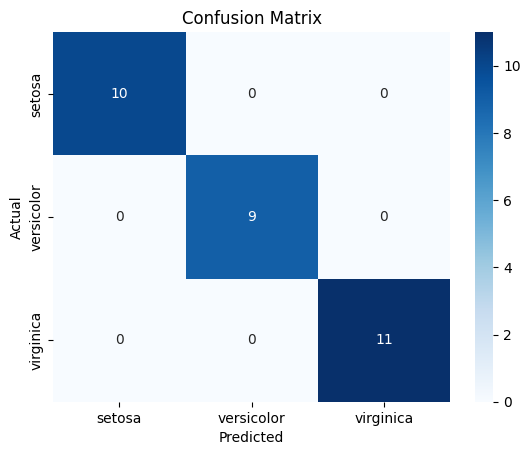

In [23]:
# Cell 2: Visualize Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [25]:
# Cell 3: Extract TN, FP, FN, TP
print(cm.ravel())
tn, fp, fn, tp = cm.ravel() if cm.shape == (2,2) else (None, None, None, None)
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")

[10  0  0  0  9  0  0  0 11]
True Negatives: None
False Positives: None
False Negatives: None
True Positives: None


THURSDAY - Classification Report


In [26]:
# Cell 1: Classification Report
from sklearn.metrics import classification_report
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [27]:
# Cell 2: Precision, Recall, F1
from sklearn.metrics import precision_score, recall_score, f1_score
print(f"Precision: {precision_score(y_test, predictions, average='macro'):.3f}")
print(f"Recall:    {recall_score(y_test, predictions, average='macro'):.3f}")
print(f"F1-Score:  {f1_score(y_test, predictions, average='macro'):.3f}")

Precision: 1.000
Recall:    1.000
F1-Score:  1.000


In [28]:
# Cell 3: Per-Class Metrics
report = classification_report(y_test, predictions, output_dict=True)
import pandas as pd
df_report = pd.DataFrame(report).transpose()
print(df_report.round(3))

              precision  recall  f1-score  support
setosa              1.0     1.0       1.0     10.0
versicolor          1.0     1.0       1.0      9.0
virginica           1.0     1.0       1.0     11.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0     30.0
weighted avg        1.0     1.0       1.0     30.0


FRIDAY - Accuracy Limitations & Imbalanced Data

In [29]:
# Cell 1: Accuracy on Imbalanced Data
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=1000, weights=[0.95, 0.05], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, pred):.2%}")
print("But data is imbalanced: 95% class 0, 5% class 1")

Accuracy: 93.50%
But data is imbalanced: 95% class 0, 5% class 1


In [ ]:
# Cell 2: Better Metrics for Imbalanced Data
from sklearn.metrics import classification_report
print(classification_report(y_test, pred))
print("Notice: Recall for class 1 may be very low")

In [ ]:
# Cell 3: Summary of Classification Metrics
print("Classification Summary:")
print("- Accuracy: Overall correct predictions")
print("- Precision: Of predicted positives, how many are correct")
print("- Recall: Of actual positives, how many were found")
print("- F1-Score: Balance of precision and recall")
print("- Use F1 and recall for imbalanced datasets")

#WEEK 10: Building a Regression Model

MONDAY - Linear Regression


In [ ]:
# Cell 1: Training Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import pandas as pd
import io

csv_data = """Area,Bedrooms,Age,Price
1000,2,10,200000
1500,3,5,300000
1200,2,8,240000
1800,4,3,360000
900,1,15,150000
2000,4,2,400000"""
df = pd.read_csv(io.StringIO(csv_data))
X = df[['Area', 'Bedrooms', 'Age']]
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Coefficients: {model.coef_}")

In [ ]:
# Cell 2: Predictions
pred = model.predict(X_test)
print(f"Predicted: {pred}")
print(f"Actual:    {y_test.values}")

In [ ]:
# Cell 3: Compare Predictions
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': pred.round(0)
})
print(comparison)

TUESDAY - Making Predictions

In [ ]:
# Cell 1: Predict on New Data
new_data = pd.DataFrame({
    'Area': [1300],
    'Bedrooms': [3],
    'Age': [6]
})
prediction = model.predict(new_data)
print(f"Predicted price for new house: ${prediction[0]:,.2f}")

In [ ]:
# Cell 2: Multiple Predictions
new_houses = pd.DataFrame({
    'Area': [1100, 1600, 2200],
    'Bedrooms': [2, 3, 5],
    'Age': [7, 4, 1]
})
predictions = model.predict(new_houses)
for i, p in enumerate(predictions):
    print(f"House {i+1}: ${p:,.2f}")

In [ ]:
# Cell 3: Visualize Predictions
import matplotlib.pyplot as plt
plt.scatter(y_test, pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.show()

WEDNESDAY - MAE and MSE


In [ ]:
# Cell 1: Mean Absolute Error
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, pred)
print(f"MAE: ${mae:,.2f}")
print("Average absolute difference between predicted and actual")

In [ ]:
# Cell 2: Mean Squared Error
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, pred)
print(f"MSE: {mse:,.2f}")
print(f"RMSE: ${mse**0.5:,.2f}")

In [ ]:
# Cell 3: Compare Metrics
print("Regression Metrics:")
print(f"MAE : ${mae:,.2f} - Average error")
print(f"MSE : {mse:,.2f} - Penalizes large errors")
print(f"RMSE: ${mse**0.5:,.2f} - Same units as target")